In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json
import math
import os

import cv2
from PIL import Image
import numpy as np
from keras import layers
from keras.applications import DenseNet121
from keras.callbacks import Callback, ModelCheckpoint
from keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential
from keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score
import scipy
import tensorflow as tf
from tqdm import tqdm

%matplotlib inline

Set random seed for reproducibility.

In [ ]:
np.random.seed(2019)
#tf.set_random_seed(2019)
tf.random.set_seed(2019)

# Loading & Exploration

In [ ]:
train_df = pd.read_csv('/content/drive/MyDrive/aptos2019-blindness-detection/train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/aptos2019-blindness-detection/test.csv')
print(train_df.shape)
print(test_df.shape)
train_df.head()

(3662, 2)
(1928, 1)


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [ ]:
!nvidia-smi

Thu Mar 14 03:55:40 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   34C    P8               9W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

### Displaying some Sample Images

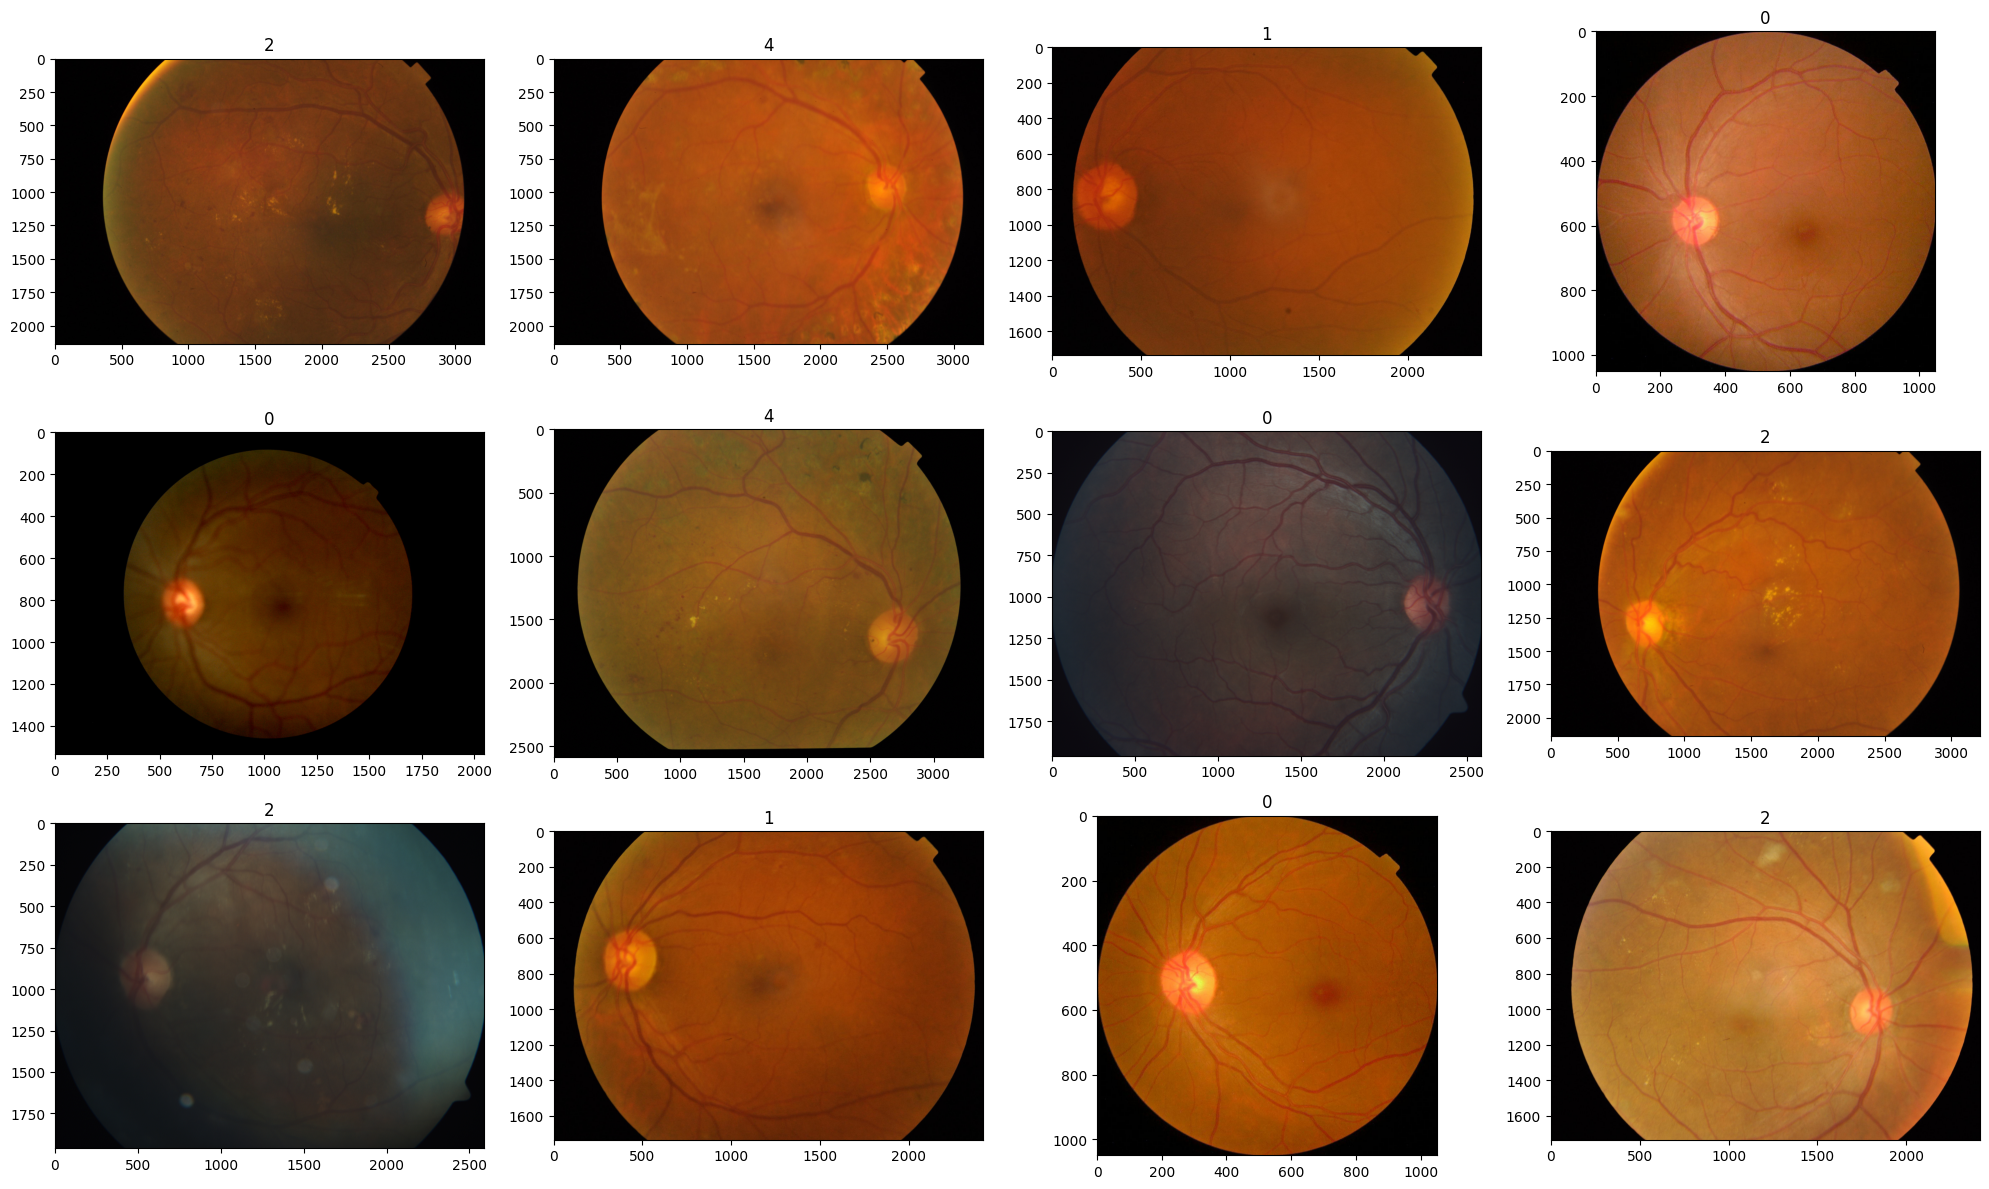

In [ ]:
def display_samples(df, columns=4, rows=3):
    fig=plt.figure(figsize=(5*columns, 4*rows))

    for i in range(columns*rows):
        image_path = df.loc[i,'id_code']
        image_id = df.loc[i,'diagnosis']
        img = cv2.imread(f'/content/drive/MyDrive/aptos2019-blindness-detection/train_images/{image_path}.png')
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        fig.add_subplot(rows, columns, i+1)
        plt.title(image_id)
        plt.imshow(img)

    plt.tight_layout()

display_samples(train_df)

# Resize Images

We will resize the images to 224x224, then create a single numpy array to hold the data.

In [ ]:
def preprocess_image(image_path, desired_size=224):
    im = Image.open(image_path)
    im = im.resize((desired_size, )*2, resample=Image.LANCZOS)

    return im

In [ ]:
# Define paths
output_path_train = '/content/drive/My Drive/aptos2019-blindness-detection/preprocessed_train/'
output_path_test = '/content/drive/My Drive/aptos2019-blindness-detection/preprocessed_test/'

In [ ]:
N = train_df.shape[0]
x_train = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(train_df['id_code'])):
    image = preprocess_image(
        f'/content/drive/MyDrive/aptos2019-blindness-detection/train_images/{image_id}.png'
    )
    x_train[i, :, :, :] = np.array(image)
    image.save(output_path_train + f'{image_id}.png')

100%|██████████| 3662/3662 [30:19<00:00,  2.01it/s]


In [ ]:
N = test_df.shape[0]
x_test = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(test_df['id_code'])):
    image = preprocess_image(
        f'/content/drive/MyDrive/aptos2019-blindness-detection/test_images/{image_id}.png'
    )
    x_test[i, :, :, :] = np.array(image)
    image.save(output_path_test + f'{image_id}.png')

100%|██████████| 1928/1928 [13:14<00:00,  2.43it/s]


In [ ]:
np.save('/content/drive/My Drive/aptos2019-blindness-detection/x_test.npy', x_test)
np.save('/content/drive/My Drive/aptos2019-blindness-detection/x_train.npy', x_train)

## **Load the npy arrays**

In [ ]:
# Load the saved numpy arrays
x_train = np.load('/content/drive/My Drive/aptos2019-blindness-detection/x_train.npy')
x_test = np.load('/content/drive/My Drive/aptos2019-blindness-detection/x_test.npy')

In [ ]:
y_train = pd.get_dummies(train_df['diagnosis']).values

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)

(3662, 224, 224, 3)
(3662, 5)
(1928, 224, 224, 3)


In [ ]:
y_train_multi = np.empty(y_train.shape, dtype=y_train.dtype)
y_train_multi[:, 4] = y_train[:, 4]

for i in range(3, -1, -1):
    y_train_multi[:, i] = np.logical_or(y_train[:, i], y_train_multi[:, i+1])

print("Original y_train:", y_train.sum(axis=0))
print("Multilabel version:", y_train_multi.sum(axis=0))

Original y_train: [1805  370  999  193  295]
Multilabel version: [3662 1857 1487  488  295]


In [ ]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train_multi,
    test_size=0.15,
    random_state=2019
)

In [ ]:
BATCH_SIZE = 32

def create_datagen():
    return ImageDataGenerator(
        zoom_range=0.15,  # set range for random zoom
        # set mode for filling points outside the input boundaries
        fill_mode='constant',
        cval=0.,  # value used for fill_mode = "constant"
        horizontal_flip=True,  # randomly flip images
        vertical_flip=True,  # randomly flip images
    )

# Using original generator
data_generator = create_datagen().flow(x_train, y_train, batch_size=BATCH_SIZE, seed=2019)

### Creating keras callback for QWK

In [ ]:
class Metrics(Callback):
    def __init__(self, validation_data):
        self.validation_data = validation_data

    def on_train_begin(self, logs={}):
        self.val_kappas = []

    def on_epoch_end(self, epoch, logs={}):
        X_val, y_val = self.validation_data[:2]
        y_val = y_val.sum(axis=1) - 1

        y_pred = self.model.predict(X_val) > 0.5
        y_pred = y_pred.astype(int).sum(axis=1) - 1

        _val_kappa = cohen_kappa_score(
            y_val,
            y_pred,
            weights='quadratic'
        )

        self.val_kappas.append(_val_kappa)

        print(f"val_kappa: {_val_kappa:.4f}")

        if _val_kappa == max(self.val_kappas):
            print("Validation Kappa has improved. Saving model.")
            self.model.save('my_model.keras')

        return

# Model: DenseNet-121

In [ ]:
base = DenseNet121(
    weights='/content/drive/MyDrive/DenseNet-BC-121-32-no-top.h5/DenseNet-BC-121-32-no-top.h5',
    include_top=False,
    input_shape=(224,224,3)
)

In [ ]:
def build_model():
    model = Sequential()
    model.add(base)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(5, activation='sigmoid'))

    model.compile(
        loss='binary_crossentropy',
        optimizer=Adam(learning_rate=0.00005),
        metrics=['accuracy'],
        run_eagerly=True
    )

    return model

In [ ]:
model = build_model()
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 densenet121 (Functional)    (None, 7, 7, 1024)        7037504   
                                                                 
 global_average_pooling2d (  (None, 1024)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense (Dense)               (None, 5)                 5125      
                                                                 
Total params: 7042629 (26.87 MB)
Trainable params: 6958981 (26.55 MB)
Non-trainable params: 83648 (326.75 KB)
_________________________________________________________________


# Model: InceptionV3

In [ ]:
from keras.applications import InceptionV3
base = InceptionV3(
    weights='/content/drive/MyDrive/Inception/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5',
    include_top=False,
    input_shape=(224,224,3)
)

In [ ]:
model1 = build_model()
model1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inception_v3 (Functional)   (None, 5, 5, 2048)        21802784  
                                                                 
 global_average_pooling2d_1  (None, 2048)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dropout_1 (Dropout)         (None, 2048)              0         
                                                                 
 dense_1 (Dense)             (None, 5)                 10245     
                                                                 
Total params: 21813029 (83.21 MB)
Trainable params: 21778597 (83.08 MB)
Non-trainable params: 34432 (134.50 KB)
_________________________________________________________________


# Training & Evaluation

In [ ]:
history = model.fit(
    data_generator,
    steps_per_epoch=x_train.shape[0] / BATCH_SIZE,
    epochs=50,
    validation_data=(x_val, y_val),
    callbacks=[Metrics((x_val, y_val))]
)

Epoch 1/50


18/18 [==============================] - 4s 216ms/step
val_kappa: 0.5304
Validation Kappa has improved. Saving model.


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


97/97 [==============================] - 168s 1s/step - loss: 0.4217 - accuracy: 0.4515 - val_loss: 0.4281 - val_accuracy: 0.4727
Epoch 2/50
18/18 [==============================] - 4s 240ms/step
val_kappa: 0.7951
Validation Kappa has improved. Saving model.


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


97/97 [==============================] - 113s 1s/step - loss: 0.2041 - accuracy: 0.6009 - val_loss: 0.2345 - val_accuracy: 0.6236
Epoch 3/50
18/18 [==============================] - 4s 222ms/step
val_kappa: 0.8624
Validation Kappa has improved. Saving model.


... (4 outputs left out)

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


97/97 [==============================] - 111s 1s/step - loss: 0.1282 - accuracy: 0.6234 - val_loss: 0.1046 - val_accuracy: 0.6673
Epoch 6/50
18/18 [==============================] - 4s 215ms/step
val_kappa: 0.9226
Validation Kappa has improved. Saving model.


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


97/97 [==============================] - 112s 1s/step - loss: 0.1186 - accuracy: 0.6266 - val_loss: 0.1019 - val_accuracy: 0.6655
Epoch 7/50
18/18 [==============================] - 4s 215ms/step
val_kappa: 0.9092
97/97 [==============================] - 109s 1s/step - loss: 0.1126 - accuracy: 0.6240 - val_loss: 0.1018 - val_accuracy: 0.6982
Epoch 8/50
18/18 [==============================] - 4s 224ms/step
val_kappa: 0.9130
97/97 [==============================] - 109s 1s/step - loss: 0.1015 - accuracy: 0.6228 - val_loss: 0.0965 - val_accuracy: 0.6691
Epoch 9/50
18/18 [==============================] - 4s 211ms/step
val_kappa: 0.9018
97/97 [==============================] - 108s 1s/step - loss: 0.0987 - accuracy: 0.6494 - val_loss: 0.1052 - val_accuracy: 0.6727
Epoch 10/50
18/18 [==============================] - 4s 219ms/step
val_kappa: 0.9144
97/97 [==============================] - 109s 1s/step - loss: 0.0887 - accuracy: 0.6430 - val_loss: 0.0962 - val_accuracy: 0.6855
Epoch 11/50
1

In [ ]:
history1 = model1.fit(
    data_generator,
    steps_per_epoch=x_train.shape[0] // BATCH_SIZE,
    epochs=20,
    validation_data=(x_val, y_val),
    callbacks=[Metrics((x_val, y_val))]
)

Epoch 1/20
18/18 [==============================] - 3s 171ms/step
val_kappa: 0.8371
Validation Kappa has improved. Saving model.
97/97 [==============================] - 82s 839ms/step - loss: 0.1608 - accuracy: 0.7075 - val_loss: 0.1404 - val_accuracy: 0.7564
Epoch 2/20
18/18 [==============================] - 3s 171ms/step
val_kappa: 0.8743
Validation Kappa has improved. Saving model.
97/97 [==============================] - 84s 867ms/step - loss: 0.1359 - accuracy: 0.7013 - val_loss: 0.1319 - val_accuracy: 0.7527
Epoch 3/20
18/18 [==============================] - 4s 224ms/step
val_kappa: 0.8870
Validation Kappa has improved. Saving model.
97/97 [==============================] - 87s 886ms/step - loss: 0.1252 - accuracy: 0.6880 - val_loss: 0.1268 - val_accuracy: 0.7364
Epoch 4/20
18/18 [==============================] - 4s 198ms/step
val_kappa: 0.8878
Validation Kappa has improved. Saving model.
97/97 [==============================] - 85s 871ms/step - loss: 0.1074 - accuracy: 0.689

In [ ]:
#model.load_weights('model.h5')
y_val_pred = model.predict(x_val)

18/18 [==============================] - 4s 219ms/step


## Submit

In [ ]:
import numpy as np
y_test = model.predict(x_test)
y_test1 = model1.predict(x_test)
res = y_test*0.8+y_test1*0.2
y_test = res > 0.5
#y_test = np.logical_or(y_test,y_test1)
y_test = y_test.astype(int).sum(axis=1) - 1

test_df['diagnosis'] = y_test
test_df.to_csv('predictions.csv',index=False)

61/61 [==============================] - 11s 173ms/step
